# Time series introduction and three-dataset assignment

The lesson exercise uses the repository's GEFCom2014 hourly energy file.
The assignment adds three distinct series: Mauna Loa atmospheric CO2,
annual sunspot activity, and annual Nile flow. Their complete snapshots
come from the installed statsmodels datasets and are supplied in
[data](../data/README.md). No online download is required to rerun this work.

,load,temp
timestamp,,
2012-01-01 00:00:00,2698.0,32.000000
2012-01-01 01:00:00,2558.0,32.666667
2012-01-01 02:00:00,2444.0,30.000000
2012-01-01 03:00:00,2402.0,31.000000
2012-01-01 04:00:00,2403.0,32.000000


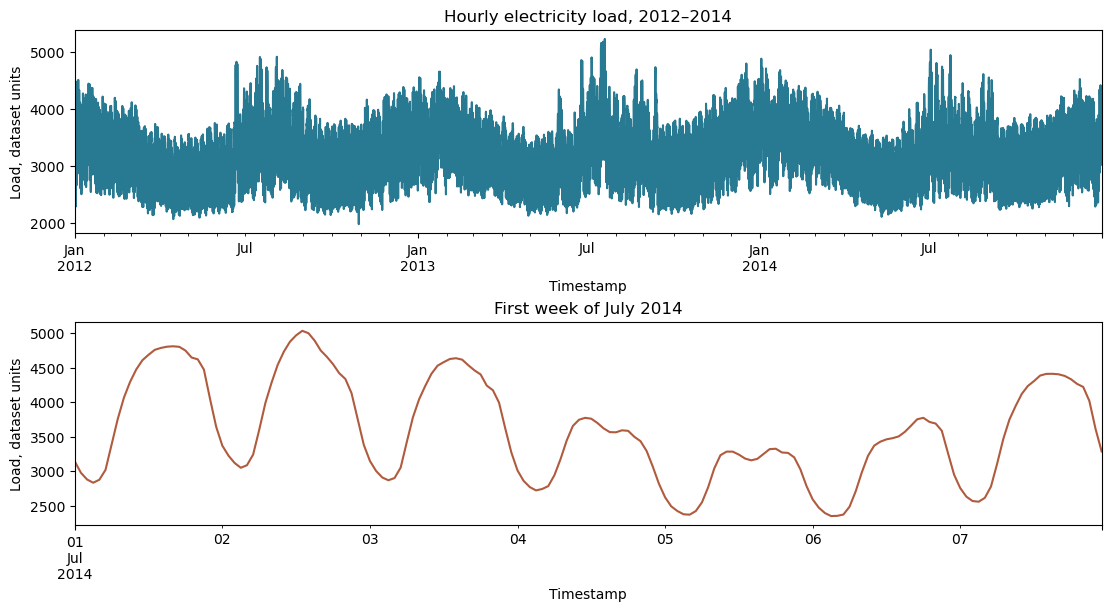

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from statsmodels.graphics.tsaplots import plot_acf

energy = pd.read_csv('../../../7-TimeSeries/data/energy.csv', parse_dates=['timestamp']).set_index('timestamp').asfreq('h')
assert energy.shape == (26304, 2)
assert energy.index.is_unique and energy.notna().all().all()
assert energy.index.min() == pd.Timestamp('2012-01-01')
assert energy.index.max() == pd.Timestamp('2014-12-31 23:00:00')
display(energy.head())
fig, axes = plt.subplots(2, 1, figsize=(11, 6), layout='constrained')
energy.load.plot(ax=axes[0], color='#287a92', title='Hourly electricity load, 2012–2014')
energy.loc['2014-07-01':'2014-07-07', 'load'].plot(ax=axes[1], color='#b05b3e', title='First week of July 2014')
for ax in axes:
    ax.set_ylabel('Load, dataset units')
    ax.set_xlabel('Timestamp')
fig.savefig('energy-overview.png', dpi=150)
plt.show()

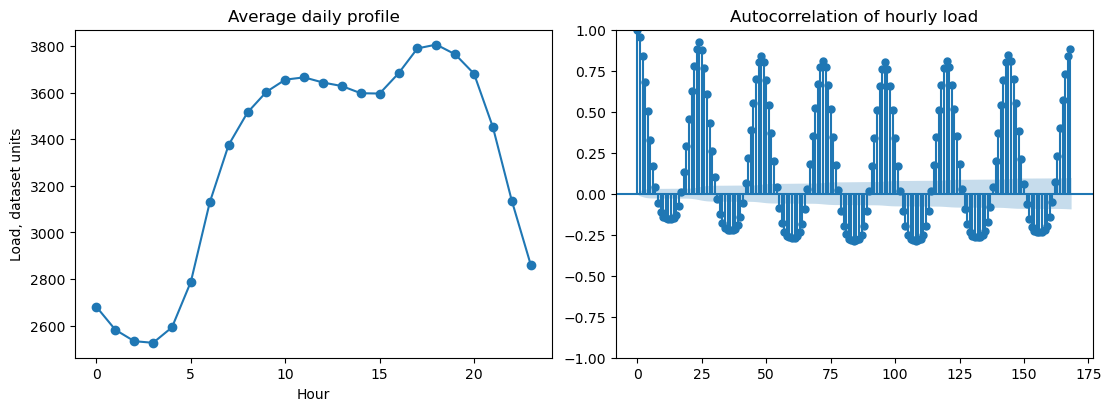

Hours: 26304 Missing hours: 0


In [2]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout='constrained')
energy.load.groupby(energy.index.hour).mean().plot(ax=axes[0], marker='o')
axes[0].set(title='Average daily profile', xlabel='Hour', ylabel='Load, dataset units')
plot_acf(energy.load, lags=24*7, ax=axes[1], title='Autocorrelation of hourly load')
fig.savefig('energy-patterns.png', dpi=150)
plt.show()
print('Hours:', len(energy), 'Missing hours:', int(energy.load.isna().sum()))

## Assignment: three other series

Each panel uses the original sampling interval. CO2 contains missing weeks;
retain them as gaps for exploration. Annual sunspots show multi-year cycles,
rather than within-year seasonality. Nile flow exhibits an apparent change
in level near 1898; the plot alone cannot establish its cause.

CO2 missing weekly observations: 59


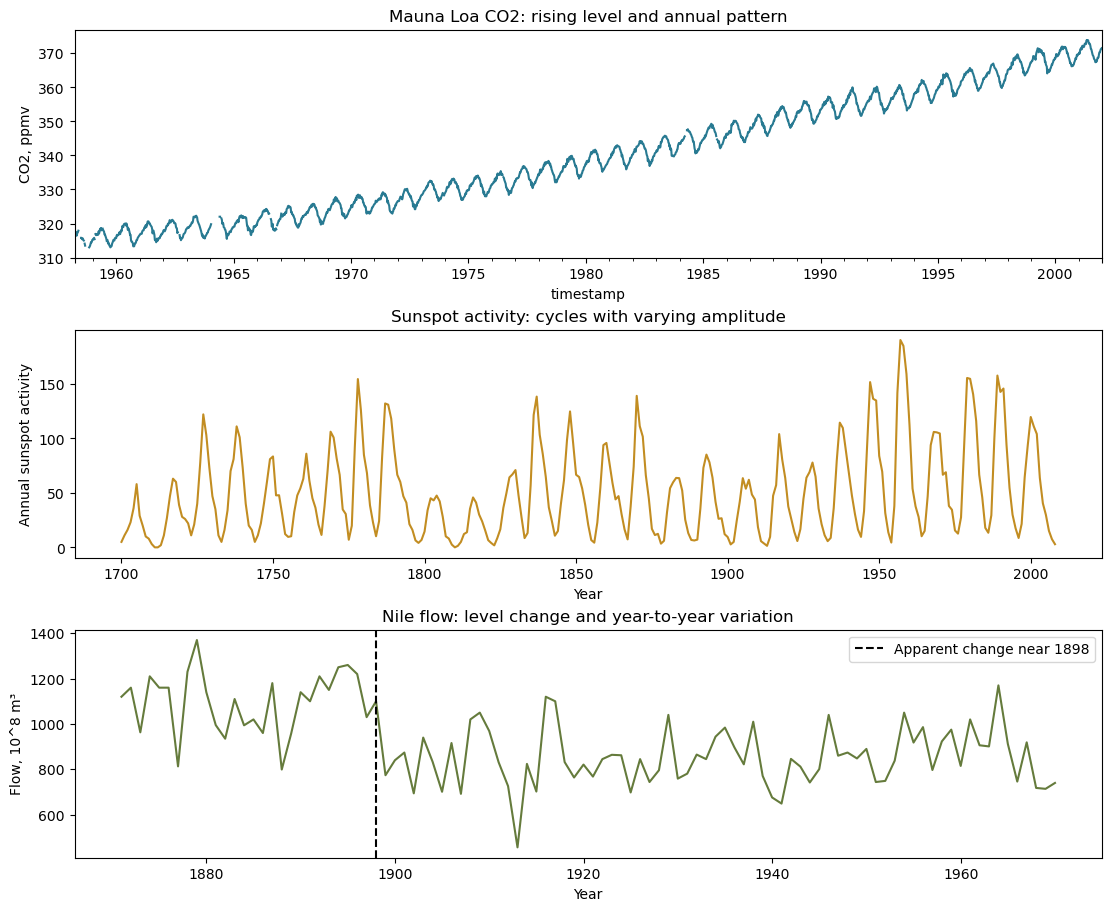

In [3]:
co2 = pd.read_csv('../data/co2.csv', parse_dates=['timestamp']).set_index('timestamp').co2
sunspots = pd.read_csv('../data/sunspots.csv')
nile = pd.read_csv('../data/nile.csv')
assert len(co2) == 2284 and len(sunspots) == 309 and len(nile) == 100
print('CO2 missing weekly observations:', int(co2.isna().sum()))
fig, axes = plt.subplots(3, 1, figsize=(11, 9), layout='constrained')
co2.plot(ax=axes[0], color='#287a92', title='Mauna Loa CO2: rising level and annual pattern')
axes[0].set_ylabel('CO2, ppmv')
axes[1].plot(sunspots.YEAR, sunspots.SUNACTIVITY, color='#c28d22')
axes[1].set(title='Sunspot activity: cycles with varying amplitude', xlabel='Year', ylabel='Annual sunspot activity')
axes[2].plot(nile.year, nile.volume, color='#657b3c')
axes[2].axvline(1898, color='black', linestyle='--', label='Apparent change near 1898')
axes[2].legend()
axes[2].set(title='Nile flow: level change and year-to-year variation', xlabel='Year', ylabel='Flow, 10^8 m³')
fig.savefig('three-time-series.png', dpi=150)
plt.show()

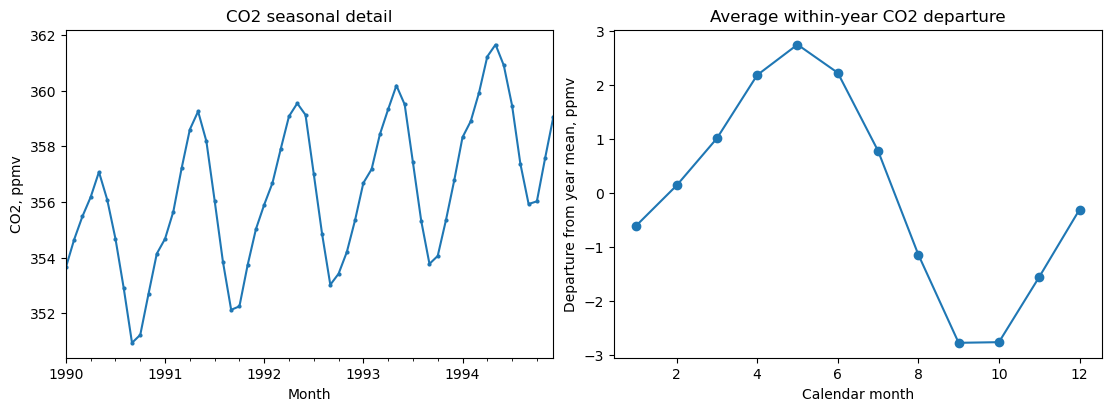

In [4]:
monthly = co2.resample('MS').mean()
# Forward fill uses earlier months only; this is also the forecast preprocessing rule.
monthly_filled = monthly.ffill()
assert monthly_filled.notna().all()
residual_from_year_mean = monthly_filled - monthly_filled.groupby(monthly_filled.index.year).transform('mean')
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout='constrained')
monthly_filled.loc['1990':'1994'].plot(ax=axes[0], marker='o', markersize=2)
axes[0].set(title='CO2 seasonal detail', xlabel='Month', ylabel='CO2, ppmv')
residual_from_year_mean.groupby(residual_from_year_mean.index.month).mean().plot(ax=axes[1], marker='o')
axes[1].set(title='Average within-year CO2 departure', xlabel='Calendar month', ylabel='Departure from year mean, ppmv')
fig.savefig('co2-seasonality.png', dpi=150)
plt.show()

## Interpretation and knowledge checks

Load has daily and weekly structure, with changing seasonal levels. A high
or low observation is not automatically bad data. Trend and seasonality are
potentially useful signal, not noise that must always be removed. The
changing variable in the lesson's CO2 table is concentration; date supplies
the time index. Observations can also be irregularly sampled, although the
quiz concentrates on regular intervals.

CO2 has a rising trend and repeated annual variation. Sunspot cycles vary
in length and amplitude, so a fixed seasonal period needs justification.
Nile flow is useful for studying a possible structural break. None of these
historical snapshots supplies evidence about current conditions. Whole-series
plots are descriptive; forecasting evaluation below uses chronological splits.

## Challenge: application areas

Arts: venue attendance and exhibit demand. Econometrics: output and
unemployment. Ecology: water flow and seasonal populations. Retail:
product demand. Industry: equipment telemetry and production loads.
Finance: liquidity and volatility. Energy: electricity demand. Transport:
traffic and transit demand. Public services: call volumes and resource
planning. The useful horizon, cost of errors, and data available at the
forecast origin differ between these examples.